In [3]:
# 作业3：Global collection of hurricanes

# 声明引入需要用到的库
import pandas as pd
import matplotlib.pyplot as plt
# 读取原始数据
df = pd.read_csv(
    "ibtracs.ALL.list.v04r00.csv",
    usecols=["SID", "SEASON", "BASIN", "NAME","ISO_TIME", "LAT", "LON", "WMO_WIND"], # 只读取作业需要用到的列
    skiprows=[1],             # 行号从0开始，只跳过第2行的单位说明
    skipinitialspace=True,    # 去掉逗号后、字段前面的空格
    keep_default_na=False,    # 保留合法海盆代码 "NA"
    na_values=["", " ", "NOT_NAMED", "NAME"],
    parse_dates=["ISO_TIME"], # 将时间列转换为日期时间
    low_memory=False         # 避免分块推断列类型带来的警告
)

# 转换一下确保经纬度和风速都是数值，将无法转换的内容变成NaN，缺失风速也同样（不能填0）
for column in ["LAT", "LON", "WMO_WIND"]:
    df[column] = pd.to_numeric(df[column], errors="coerce")
# 打印一些数据信息看看读取是否正常
print("数据形状：", df.shape)
print("开始时间：", df["ISO_TIME"].min())
print("结束时间：", df["ISO_TIME"].max())
df.head()

数据形状： (707177, 8)
开始时间： 1842-10-25 03:00:00
结束时间： 2022-10-13 00:00:00


,SID,SEASON,BASIN,NAME,ISO_TIME,LAT,LON,WMO_WIND
0,1842298N11080,1842,NI,NaN,1842-10-25 03:00:00,10.9000,80.3000,NaN
1,1842298N11080,1842,NI,NaN,1842-10-25 06:00:00,10.8709,79.8265,NaN
2,1842298N11080,1842,NI,NaN,1842-10-25 09:00:00,10.8431,79.3524,NaN
3,1842298N11080,1842,NI,NaN,1842-10-25 12:00:00,10.8188,78.8772,NaN
4,1842298N11080,1842,NI,NaN,1842-10-25 15:00:00,10.8000,78.4000,NaN


In [10]:
# 题目3.1：按SID分组，找出最大风速排名前10的风暴名称

# 同一个风暴的风速会随时间变化，因此先对每个SID取最大风速，再进行排名
# 使用agg()为不同的列指定不同的汇总方法：NAME和SEASON都是取第一个，WMO_WIND则是取该风暴全部记录中的最大风速
storm_summary = df.groupby("SID").agg({
    "NAME": "first",
    "SEASON": "first",
    "WMO_WIND": "max"
})

# 如果一个风暴的WMO_WIND全部为空值，则不参与风速排名
storm_summary = storm_summary.dropna(subset=["WMO_WIND"])

# 按最大风速降序排列，并且稳定排序使风速相同时保留原来的SID顺序
storm_summary = storm_summary.sort_values(
    "WMO_WIND",
    ascending=False,
    kind="stable"
)
top10 = storm_summary.head(10)
# 输出结果时将缺失名称写成 NOT_NAMED
print(top10.fillna({"NAME": "NOT_NAMED"}).to_string())

                    NAME  SEASON  WMO_WIND
SID                                       
2015293N13266   PATRICIA    2015     185.0
1980214N11330      ALLEN    1980     165.0
1935241N23291  NOT_NAMED    1935     160.0
1988253N12306    GILBERT    1988     160.0
1997253N12255      LINDA    1997     160.0
2005289N18282      WILMA    2005     160.0
2019236N10314     DORIAN    2019     160.0
1998295N12284      MITCH    1998     155.0
2005261N21290       RITA    2005     155.0
2009288N07267       RICK    2009     155.0


In [15]:
# 题目3.2：列出最大风速排名前20的风暴及其风速

# 直接使用上一题3.1中已经计算好的风暴汇总表：
top20 = storm_summary.head(20)
print(top20.fillna({"NAME": "NOT_NAMED"}).to_string())

# 上面的代码是按照不同的SID（即不同的风暴）取前20个风速最大的，如果只看WMO_WIND，即要“风速最高的20条观测记录”，则为如下代码
# 风速最高的 20 条记录，而非20个不同风暴，此时NAME列表中会出现同一个风暴
top20_records = df.nlargest(20, "WMO_WIND")
print("\n")
print(
    top20_records[
        ["SID", "NAME", "ISO_TIME", "WMO_WIND"]
    ].to_string(index=False)
)

                    NAME  SEASON  WMO_WIND
SID                                       
2015293N13266   PATRICIA    2015     185.0
1980214N11330      ALLEN    1980     165.0
1935241N23291  NOT_NAMED    1935     160.0
1988253N12306    GILBERT    1988     160.0
1997253N12255      LINDA    1997     160.0
2005289N18282      WILMA    2005     160.0
2019236N10314     DORIAN    2019     160.0
1998295N12284      MITCH    1998     155.0
2005261N21290       RITA    2005     155.0
2009288N07267       RICK    2009     155.0
2017242N16333       IRMA    2017     155.0
1932304N15305  NOT_NAMED    1932     150.0
1955265N13307      JANET    1955     150.0
1959249N19181      PATSY    1959     150.0
1969226N18280    CAMILLE    1969     150.0
1977242N27272      ANITA    1977     150.0
1979238N12324      DAVID    1979     150.0
1992230N11325     ANDREW    1992     150.0
1994222N11267       JOHN    1994     150.0
2005236N23285    KATRINA    2005     150.0


          SID     NAME            ISO_TIME  WMO_WIND

In [17]:
# 题目3.3：统计各海盆的数据点数量

# 这里认为一个数据点就是CSV中的一行记录，因此使用size()方法来统计
basin_counts = df.groupby("BASIN").size().sort_values(ascending=False)
print(basin_counts.to_string())
print("合计：", basin_counts.sum())

BASIN
WP    236576
SI    160668
NA    124881
SP     67119
EP     62412
NI     55402
SA       119
合计： 707177


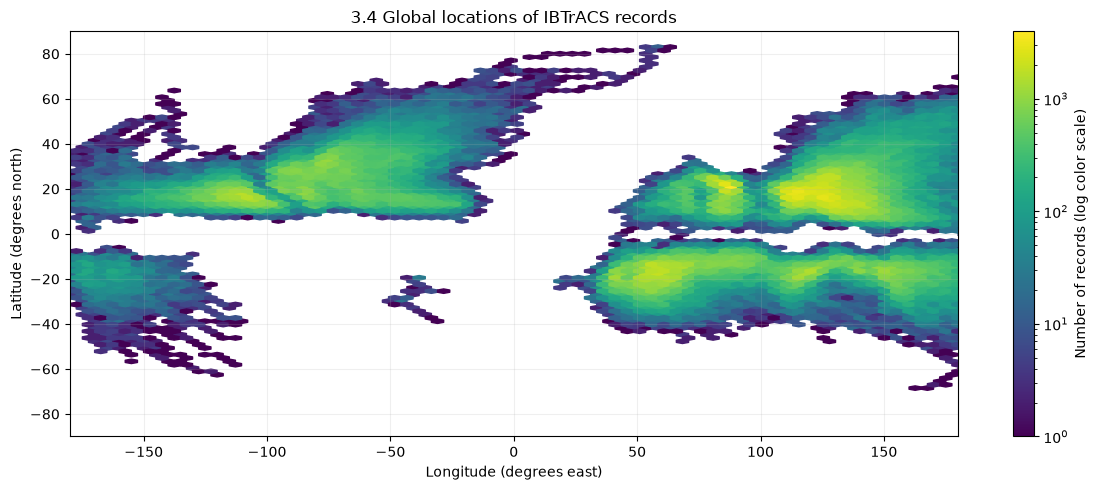

In [18]:
# 题目3.4：绘制所有数据点位置的六边形分箱图

# 参考https://www.geeksforgeeks.org/python/matplotlib-pyplot-hexbin-function-in-python/下的帮助文档绘制
# 绘图时只排除缺失经纬度的记录
locations = df.dropna(subset=["LON", "LAT"])
fig, ax = plt.subplots(figsize=(12, 5))
hexes = ax.hexbin(
    locations["LON"],
    locations["LAT"],
    gridsize=90,       # 控制分箱的精细程度
    mincnt=1,          # 不显示没有记录的格子
    bins="log",        # 使用对数颜色尺度，便于观察数量差异
    cmap="viridis"
)
fig.colorbar(
    hexes,
    ax=ax,
    label="Number of records (log color scale)"
)
ax.set(
    xlabel="Longitude (degrees east)",
    ylabel="Latitude (degrees north)",
    title="3.4 Global locations of IBTrACS records",
    xlim=(-180, 180),
    ylim=(-90, 90)
)
ax.grid(alpha=0.2)
fig.tight_layout()
plt.show()

SID： <ArrowStringArray>
['2018250N12170']
Length: 1, dtype: str
记录数： 99
开始时间： 2018-09-06 12:00:00
结束时间： 2018-09-17 18:00:00


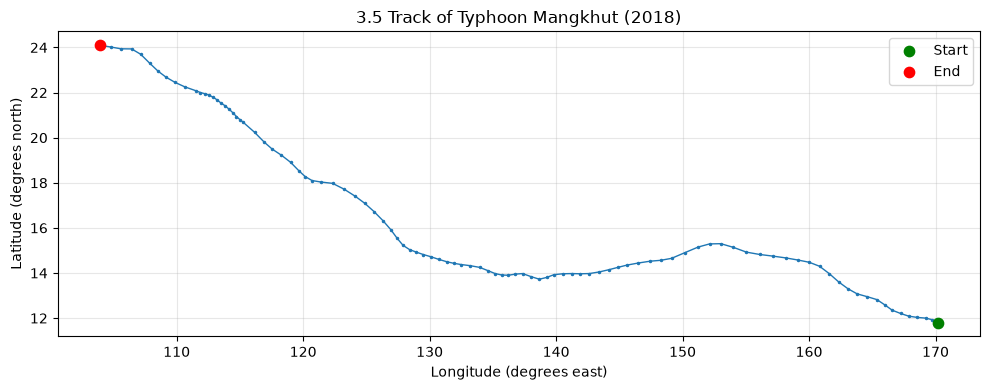

In [19]:
# 题目3.5：找出 2018 年台风山竹，并绘制路径

# 首先名称和年份需要同时进行限定，随后按时间排序后再进行连线即可
# 将2018年的台风山竹筛选出来
mangkhut = df[
    (df["NAME"] == "MANGKHUT") &
    (df["SEASON"] == 2018)
].sort_values("ISO_TIME")
# 打印一些山竹的相关信息
print("SID：", mangkhut["SID"].unique())
print("记录数：", len(mangkhut))
print("开始时间：", mangkhut["ISO_TIME"].min())
print("结束时间：", mangkhut["ISO_TIME"].max())

# 创建画布和子图变量
fig, ax = plt.subplots(figsize=(10, 4))
# 按时间先后连接各个位置。
ax.plot(mangkhut["LON"], mangkhut["LAT"],".-",markersize=3,linewidth=1)
# iloc[0]和iloc[-1]分别表示第一行和最后一行，起始点和终点分别用绿色和红色的点标识出来
ax.scatter(
    mangkhut["LON"].iloc[0],
    mangkhut["LAT"].iloc[0],
    color="green", s=55, label="Start", zorder=3
)
ax.scatter(
    mangkhut["LON"].iloc[-1],
    mangkhut["LAT"].iloc[-1],
    color="red", s=55, label="End", zorder=3
)
ax.set(
    xlabel="Longitude (degrees east)",
    ylabel="Latitude (degrees north)",
    title="3.5 Track of Typhoon Mangkhut (2018)"
)
ax.legend()
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

In [4]:
# 题目3.6：筛选出一个1970年以来WP、EP海盆的数据集

# 按照题目要求，从本题开始，后续分析均使用筛选后的pacific数据集
# 使用isin()判断BASIN是否属于给定的海盆列表，使用&运算符同时满足时间和地点两个条件
pacific = df[(df["ISO_TIME"] >= "1970-01-01")&df["BASIN"].isin(["WP", "EP"])].copy()
print("筛选后形状：", pacific.shape)
print(pacific.groupby("BASIN").size().to_string())

筛选后形状： (176352, 8)
BASIN
EP     54051
WP    122301


总天数： 19279
每日数量合计： 176352


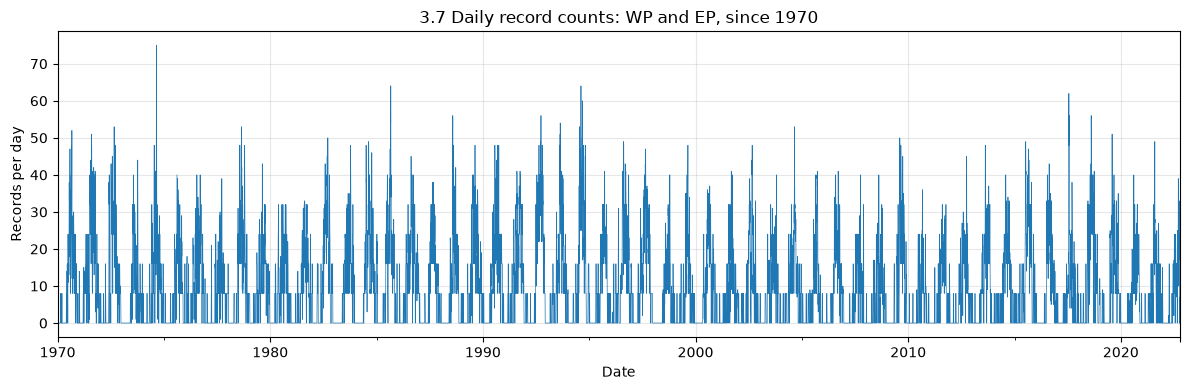

In [5]:
# 题目3.7：绘制每日的数据点数量图

# 使用resample("D")按天重采样，用size()统计每天包含多少行记录，注意重采样需要日期时间索引
daily_counts = (
    pacific.set_index("ISO_TIME")
           .resample("D")
           .size()
)
# 前面resample只补齐首条记录到末条记录之间的日期，这里进一步补齐1970年初至整个文件最后一天的日期
all_days = pd.date_range(
    start="1970-01-01",
    end=df["ISO_TIME"].max().normalize(),
    freq="D"
)
# 没有记录的日期计为0，也要参与后面的气候态平均，这里的0表示文件中没有WP、EP的记录
daily_counts = daily_counts.reindex(all_days, fill_value=0)
daily_counts.index.name = "DATE"
daily_counts.name = "count"
#打印输出相关记录
print("总天数：", len(daily_counts))
print("每日数量合计：", daily_counts.sum())

# 绘制每日数据点数量图
fig, ax = plt.subplots(figsize=(12, 4))
daily_counts.plot(ax=ax, linewidth=0.5)
ax.set(
    xlabel="Date",
    ylabel="Records per day",
    title="3.7 Daily record counts: WP and EP, since 1970"
)
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

day_of_year
1    1.566
2    1.358
3    1.396
4    1.755
5    1.981
气候态最大值的日序号： 222
对应平均记录数： 26.623


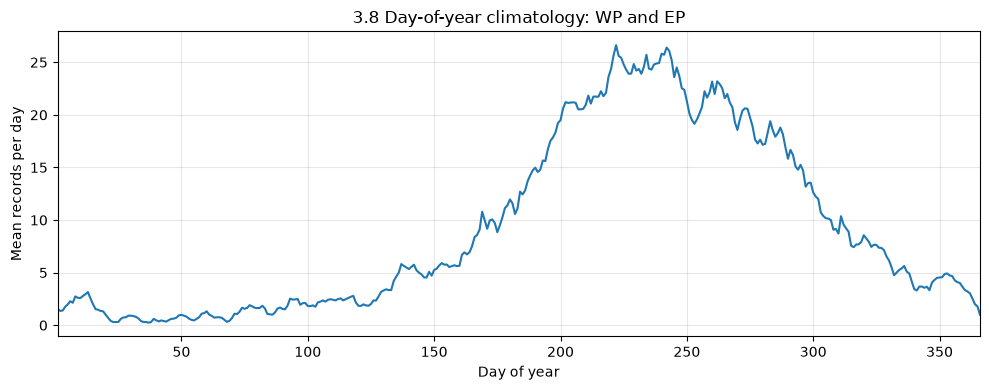

In [6]:
# 题目3.8：按年内日序号计算每日记录数的气候态

# 根据题目：“气候态”指的是：将不同年份中相同日序号的每日记录数取平均，比如第1天的气候态是各年1月1日记录数的平均值
# 将每日计数 Series 转为 DataFrame，便于添加其他列
daily_result = daily_counts.to_frame()
# dayofyear：1月1日为1，闰年最多到366
daily_result["day_of_year"] = daily_result.index.dayofyear
# 使用整个可用时段，计算相同日序号的多年平均记录数
climatology = (
    daily_result.groupby("day_of_year")["count"]
                .mean()
)
# 打印输出相关记录
print(climatology.head().round(3).to_string())
print("气候态最大值的日序号：", climatology.idxmax())
print("对应平均记录数：", round(climatology.max(), 3))

# 绘制气候态图
fig, ax = plt.subplots(figsize=(10, 4))
climatology.plot(ax=ax)
ax.set(
    xlabel="Day of year",
    ylabel="Mean records per day",
    title="3.8 Day-of-year climatology: WP and EP",
    xlim=(1, 366)
)
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

In [8]:
# 题目3.9：计算每日记录数相对于气候态的距平

#根据题意，计算公式应该为：每日距平 = 当天记录数 - 该日序号的气候态
# map()根据每一行的day_of_year，找到climatology中对应的平均记录数
daily_result["climatology"] = (
    daily_result["day_of_year"].map(climatology)
)
# 气候态已经对应到每一天，可以逐行相减
daily_result["anomaly"] = (
    daily_result["count"] - daily_result["climatology"]
)
# 打印head()距平信息
print(
    daily_result[
        ["count", "climatology", "anomaly"]
    ].head(20).round(3).to_string()
)

            count  climatology  anomaly
DATE                                   
1970-01-01      0        1.566   -1.566
1970-01-02      0        1.358   -1.358
1970-01-03      0        1.396   -1.396
1970-01-04      0        1.755   -1.755
1970-01-05      0        1.981   -1.981
1970-01-06      0        2.283   -2.283
1970-01-07      0        2.132   -2.132
1970-01-08      0        2.736   -2.736
1970-01-09      0        2.604   -2.604
1970-01-10      0        2.585   -2.585
1970-01-11      0        2.774   -2.774
1970-01-12      0        2.943   -2.943
1970-01-13      0        3.151   -3.151
1970-01-14      0        2.547   -2.547
1970-01-15      0        2.000   -2.000
1970-01-16      0        1.528   -1.528
1970-01-17      0        1.472   -1.472
1970-01-18      0        1.358   -1.358
1970-01-19      0        1.321   -1.321
1970-01-20      0        1.000   -1.000


正距平最大的 5 年：
      annual_mean_anomaly
YEAR                     
1992                4.541
1994                4.420
1997                3.335
1990                3.077
2015                3.072

负距平最大的 5 年：
      annual_mean_anomaly
YEAR                     
2010               -4.567
1998               -2.827
2021               -2.748
2007               -2.558
1973               -2.553


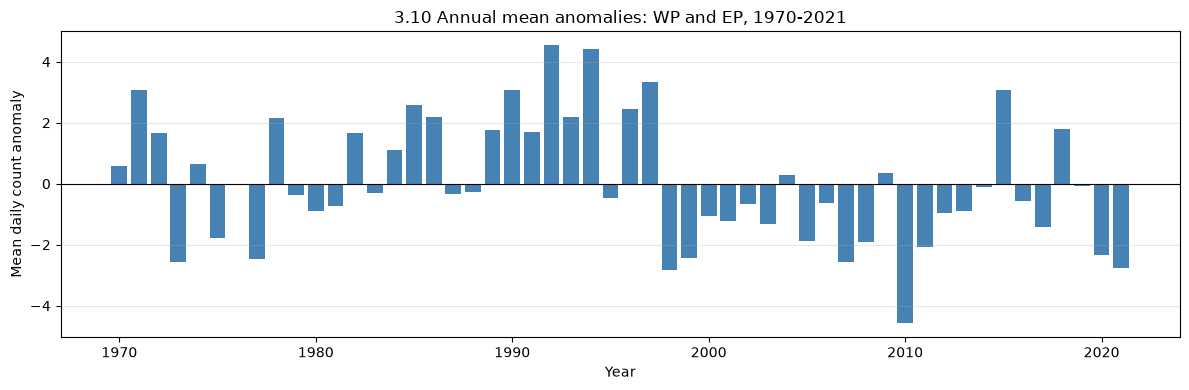

In [11]:
# 题目3.10：将距平按年重采样到年尺度并绘图，并找出异常年份

# 题目没有指定年尺度的聚合方法，这里采用每日距平的年平均，单位仍为“记录数/天”，而原始数据只到2022年10月，因此年度比较使用完整的1970—2021年
# YS表示按年分组，并以每年年初作为结果的时间标签
annual_anomaly = (
    daily_result["anomaly"]
    .resample("YS")
    .mean()
)
# 因为源数据的2022年不完整，所以年度比较时排除
annual_complete = annual_anomaly[
    annual_anomaly.index.year < 2022
]
# 打印时将日期索引换成年份，便于阅读
annual_table = annual_complete.to_frame("annual_mean_anomaly")
annual_table.index = annual_table.index.year
annual_table.index.name = "YEAR"

# 打印正负距平最大的突出年份相关信息
print("正距平最大的 5 年：")
print(
    annual_table.nlargest(
        5, "annual_mean_anomaly"
    ).round(3).to_string()
)
print("\n负距平最大的 5 年：")
print(
    annual_table.nsmallest(
        5, "annual_mean_anomaly"
    ).round(3).to_string()
)

# 绘制距平数据的年尺度时间序列图像
fig, ax = plt.subplots(figsize=(12, 4))
ax.bar(
    annual_complete.index.year,
    annual_complete.values,
    color="steelblue"
)
# 零线便于区分正、负距平
ax.axhline(0, color="black", linewidth=0.8)
ax.set(
    xlabel="Year",
    ylabel="Mean daily count anomaly",
    title="3.10 Annual mean anomalies: WP and EP, 1970-2021"
)
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
plt.show()